In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


In [2]:
!pip install --no-cache-dir \
    torch==2.7.0 torchvision==0.22.0 \
    --index-url https://download.pytorch.org/whl/cu126

Looking in indexes: https://download.pytorch.org/whl/cu126


In [3]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert torch.cuda.is_available()
assert torch.__version__.startswith("2.7.0")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.7.0+cu126
PyTorch CUDA: 12.6
CUDA available: True
GPU: Tesla T4


In [4]:
!python -m pip show torch torchvision
!python -m pip --version

Name: torch
Version: 2.7.0+cu126
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org/
Author: PyTorch Team
Author-email: packages@pytorch.org
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: filelock, fsspec, jinja2, networkx, nvidia-cublas-cu12, nvidia-cuda-cupti-cu12, nvidia-cuda-nvrtc-cu12, nvidia-cuda-runtime-cu12, nvidia-cudnn-cu12, nvidia-cufft-cu12, nvidia-cufile-cu12, nvidia-curand-cu12, nvidia-cusolver-cu12, nvidia-cusparse-cu12, nvidia-cusparselt-cu12, nvidia-nccl-cu12, nvidia-nvjitlink-cu12, nvidia-nvtx-cu12, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, easyocr, fastai, kornia, peft, pytorch-ignite, pytorch-lightning, sentence-transformers, timm, torchdata, torchmetrics, torchvision
---
Name: torchvision
Version: 0.22.0+cu126
Summary: image and video datasets and models for torch deep learning
Home-page: https://github.com/pytorch/vision
Author: PyTorch Co

In [5]:
%cd /kaggle/working

!git clone --recursive https://github.com/princeton-vl/DROID-SLAM.git

%cd /kaggle/working/DROID-SLAM

!git submodule status

/kaggle/working
fatal: destination path 'DROID-SLAM' already exists and is not an empty directory.
/kaggle/working/DROID-SLAM
 7f687644fcea81ab337831749445224503c1290d thirdparty/lietorch (7f68764)
 6cf77c420f837a427b0d57965e414d68c1bd89ec thirdparty/pytorch_scatter (2.1.2-14-g6cf77c4)


In [6]:
%cd /kaggle/working/DROID-SLAM

!pip install wheel setuptools ninja
!pip install tqdm scipy opencv-python pyyaml tensorboard
!pip install evo

/kaggle/working/DROID-SLAM


In [7]:
!nvcc --version
!which nvcc

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Fri_Feb_21_20:23:50_PST_2025
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0
/usr/local/cuda/bin/nvcc


In [8]:
%cd /kaggle/working/DROID-SLAM

!MAX_JOBS=2 TORCH_CUDA_ARCH_LIST="7.5" \
    pip install -v --no-build-isolation ./thirdparty/lietorch

/kaggle/working/DROID-SLAM
Using pip 24.1.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
Processing ./thirdparty/lietorch
  Running command python setup.py egg_info
  running egg_info
  creating /tmp/pip-pip-egg-info-06z8j2e9/lietorch.egg-info
  writing /tmp/pip-pip-egg-info-06z8j2e9/lietorch.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-pip-egg-info-06z8j2e9/lietorch.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-pip-egg-info-06z8j2e9/lietorch.egg-info/top_level.txt
  writing manifest file '/tmp/pip-pip-egg-info-06z8j2e9/lietorch.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-pip-egg-info-06z8j2e9/lietorch.egg-info/SOURCES.txt'
  adding license file 'LICENSE'
  writing manifest file '/tmp/pip-pip-egg-info-06z8j2e9/lietorch.egg-info/SOURCES.txt'
  Preparing metadata (setup.py) ... done
  Running command python setup.py bdist_wheel
  running bdist_wheel
  running build
  running build_py
  copying lietorch/gradcheck.py -> build/

In [9]:
%cd /kaggle/working/DROID-SLAM

!MAX_JOBS=2 TORCH_CUDA_ARCH_LIST="7.5" \
    pip install -v --no-build-isolation ./thirdparty/pytorch_scatter

/kaggle/working/DROID-SLAM
Using pip 24.1.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
Processing ./thirdparty/pytorch_scatter
  Running command Preparing metadata (pyproject.toml)
  /usr/local/lib/python3.13/dist-packages/setuptools/dist.py:765: SetuptoolsDeprecationWarning: License classifiers are deprecated.
  !!

          ********************************************************************************
          Please consider removing the following classifiers in favor of a SPDX license expression:

          License :: OSI Approved :: MIT License

          See https://packaging.python.org/en/latest/guides/writing-pyproject-toml/#license for details.
          ********************************************************************************

  !!
    self._finalize_license_expression()
  running dist_info
  creating /tmp/pip-modern-metadata-vhc3biks/torch_scatter.egg-info
  writing /tmp/pip-modern-metadata-vhc3biks/torch_scatter.egg-info/PKG-INFO
  writing dep

In [10]:
%cd /kaggle/working/DROID-SLAM

!MAX_JOBS=2 TORCH_CUDA_ARCH_LIST="7.5" \
    pip install -v --no-build-isolation --no-deps .

/kaggle/working/DROID-SLAM
Using pip 24.1.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
Processing /kaggle/working/DROID-SLAM
  Running command python setup.py egg_info
  running egg_info
  creating /tmp/pip-pip-egg-info-ed2i_glw/droid_backends.egg-info
  writing /tmp/pip-pip-egg-info-ed2i_glw/droid_backends.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-pip-egg-info-ed2i_glw/droid_backends.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-pip-egg-info-ed2i_glw/droid_backends.egg-info/top_level.txt
  writing manifest file '/tmp/pip-pip-egg-info-ed2i_glw/droid_backends.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-pip-egg-info-ed2i_glw/droid_backends.egg-info/SOURCES.txt'
  adding license file 'LICENSE'
  writing manifest file '/tmp/pip-pip-egg-info-ed2i_glw/droid_backends.egg-info/SOURCES.txt'
  Preparing metadata (setup.py) ... done
  Running command python setup.py bdist_wheel
  running bdist_wheel
  running build
  running bui

In [11]:
%cd /kaggle/working/DROID-SLAM

import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

import lietorch
print("LieTorch: OK")

import droid_backends
print("DROID backends: OK")

/kaggle/working/DROID-SLAM
PyTorch: 2.7.0+cu126
CUDA available: True
LieTorch: OK
DROID backends: OK


In [12]:
import torch
import lietorch
import droid_backends

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("LieTorch and DROID backend imported successfully")

PyTorch: 2.7.0+cu126
CUDA: 12.6
LieTorch and DROID backend imported successfully


In [13]:
%cd /kaggle/working/DROID-SLAM

!bash tools/download_model.sh
!ls -lh droid.pth

/kaggle/working/DROID-SLAM
Downloading...
From: https://drive.google.com/uc?id=1PpqVt1H4maBa_GbPJp4NwxRsd9jk-elh
To: /kaggle/working/DROID-SLAM/droid.pth
100%|███████████████████████████████████████| 16.1M/16.1M [00:00<00:00, 201MB/s]
-rw-r--r-- 1 root root 16M Sep  1  2021 droid.pth


In [14]:
%cd /kaggle/working

!wget -c \
  https://cvg.cit.tum.de/rgbd/dataset/freiburg3/rgbd_dataset_freiburg3_long_office_household.tgz \
  -O fr3_office.tgz

!tar -xzf fr3_office.tgz

!ls rgbd_dataset_freiburg3_long_office_household

/kaggle/working
--2026-10-16 06:15:16--  https://cvg.cit.tum.de/rgbd/dataset/freiburg3/rgbd_dataset_freiburg3_long_office_household.tgz
Resolving cvg.cit.tum.de (cvg.cit.tum.de)... 131.159.19.110, 2a09:80c0:18::1110
Connecting to cvg.cit.tum.de (cvg.cit.tum.de)|131.159.19.110|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://webshare.cvg.cit.tum.de/g/rgbd/dataset/freiburg3/rgbd_dataset_freiburg3_long_office_household.tgz [following]
--2026-10-16 06:15:18--  https://webshare.cvg.cit.tum.de/g/rgbd/dataset/freiburg3/rgbd_dataset_freiburg3_long_office_household.tgz
Resolving webshare.cvg.cit.tum.de (webshare.cvg.cit.tum.de)... 131.159.19.221, 2a09:80c0:18::1221
Connecting to webshare.cvg.cit.tum.de (webshare.cvg.cit.tum.de)|131.159.19.221|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1483556251 (1.4G) [application/x-gzip]
Saving to: ‘fr3_office.tgz’

fr3_office.tgz      100%[===================>]   1.38G  18.8MB/s    in 81s  

In [15]:
from pathlib import Path

DATASET = Path(
    "/kaggle/working/rgbd_dataset_freiburg3_long_office_household"
)

assert (DATASET / "rgb").is_dir()
assert (DATASET / "groundtruth.txt").is_file()

rgb_files = sorted((DATASET / "rgb").glob("*.png"))
print("RGB frames:", len(rgb_files))
print("First frame:", rgb_files[0].name)

RGB frames: 2585
First frame: 1341847980.722988.png


In [16]:
%cd /kaggle/working/DROID-SLAM

!cat calib/tum3.txt

/kaggle/working/DROID-SLAM
535.4 539.2 320.1 247.6

In [17]:

%cd /kaggle/working

!pip -q install remotezip

import os
from pathlib import Path
from remotezip import RemoteZip

root = Path("/kaggle/working/KITTI")
root.mkdir(parents=True, exist_ok=True)

url = "https://s3.eu-central-1.amazonaws.com/avg-kitti/data_odometry_gray.zip"
sequence_dir = root / "sequences" / "07"
sequence_dir.mkdir(parents=True, exist_ok=True)

print("Inspecting KITTI archive remotely...")
with RemoteZip(url) as z:
    members = [
        name for name in z.namelist()
        if "/sequences/07/" in name
        or name.startswith("sequences/07/")
    ]
    print("Files selected:", len(members))
    if not members:
        raise RuntimeError("Sequence 07 was not found in the archive.")

    # Download and extract only sequence 07.
    z.extractall(path=root, members=members)

print("Sequence 07 extraction complete.")
print("Left images:", len(list((sequence_dir / "image_0").glob("*.png"))))
print("Right images:", len(list((sequence_dir / "image_1").glob("*.png"))))


/kaggle/working
Inspecting KITTI archive remotely...
Files selected: 2207
Sequence 07 extraction complete.
Left images: 0
Right images: 0


In [18]:

import urllib.request
import zipfile
from pathlib import Path

root = Path("/kaggle/working/KITTI")
root.mkdir(parents=True, exist_ok=True)

archives = {
    "poses": "https://s3.eu-central-1.amazonaws.com/avg-kitti/data_odometry_poses.zip",
    "calib": "https://s3.eu-central-1.amazonaws.com/avg-kitti/data_odometry_calib.zip",
}

for name, url in archives.items():
    archive_path = root / f"{name}.zip"

    if not archive_path.exists():
        print("Downloading", name)
        urllib.request.urlretrieve(url, archive_path)

    with zipfile.ZipFile(archive_path) as z:
        selected = [
            member for member in z.namelist()
            if member.endswith("/07.txt")
            or member.endswith("/07/calib.txt")
            or member.endswith("/07/times.txt")
        ]
        print(name, "selected files:", selected)
        z.extractall(root, members=selected)

print("Ground-truth and calibration extraction complete.")


poses selected files: ['dataset/poses/07.txt']
calib selected files: ['dataset/sequences/07/calib.txt', 'dataset/sequences/07/times.txt']
Ground-truth and calibration extraction complete.


In [19]:

from pathlib import Path

root = Path("/kaggle/working/KITTI")

for p in [
    root / "sequences/07/image_0",
    root / "sequences/07/image_1",
    root / "sequences/07/calib.txt",
    root / "poses/07.txt",
]:
    print(("OK      " if p.exists() else "MISSING "), p)


MISSING  /kaggle/working/KITTI/sequences/07/image_0
MISSING  /kaggle/working/KITTI/sequences/07/image_1
MISSING  /kaggle/working/KITTI/sequences/07/calib.txt
MISSING  /kaggle/working/KITTI/poses/07.txt


In [20]:
from pathlib import Path

repo = Path("/kaggle/working/DROID-SLAM")
source = (repo / "demo.py").read_text()

old_arg = 'parser.add_argument("--reconstruction_path", help="path to saved reconstruction")'
new_arg = old_arg + '\n    parser.add_argument("--trajectory_out", default="fr3_office_estimate.txt")'

old_run = "traj_est = droid.terminate(image_stream(args.imagedir, args.calib, args.stride))"

new_run = '''traj_est = droid.terminate(
        image_stream(args.imagedir, args.calib, args.stride)
    )

    # Match the estimated poses to the timestamps of the processed RGB images.
    image_files = sorted(
        f for f in os.listdir(args.imagedir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    )[::args.stride]

    timestamps = np.array([
        float(os.path.splitext(f)[0]) for f in image_files
    ])

    if len(timestamps) != len(traj_est):
        raise RuntimeError(
            f"Timestamp/trajectory mismatch: {len(timestamps)} timestamps, "
            f"{len(traj_est)} poses"
        )

    # DROID-SLAM returns [tx, ty, tz, qw, qx, qy, qz].
    # TUM trajectory format requires [timestamp, tx, ty, tz, qx, qy, qz, qw].
    tum_trajectory = np.column_stack([
        timestamps,
        traj_est[:, :3],
        traj_est[:, 4:7],
        traj_est[:, 3]
    ])

    np.savetxt(args.trajectory_out, tum_trajectory, fmt="%.9f")
    print(f"Saved estimated trajectory: {args.trajectory_out}")
'''

assert old_arg in source, "Could not find the expected demo.py argument"
assert old_run in source, "Could not find the expected trajectory call"

modified = source.replace(old_arg, new_arg, 1)
modified = modified.replace(old_run, new_run, 1)

(repo / "run_tum_fr3.py").write_text(modified)
print("Created:", repo / "run_tum_fr3.py")

Created: /kaggle/working/DROID-SLAM/run_tum_fr3.py


In [ ]:
%cd /kaggle/working/DROID-SLAM

!python run_tum_fr3.py \
  --imagedir /kaggle/working/rgbd_dataset_freiburg3_long_office_household/rgb \
  --calib calib/tum3.txt \
  --weights droid.pth \
  --stride 1 \
  --disable_vis \
  --trajectory_out /kaggle/working/fr3_office_estimate.txt

/kaggle/working/DROID-SLAM
0it [00:00, ?it/s]droid.pth
2585it [01:49, 23.68it/s]
################################
################################
Saved estimated trajectory: /kaggle/working/fr3_office_estimate.txt


In [ ]:
GT = "/kaggle/working/rgbd_dataset_freiburg3_long_office_household/groundtruth.txt"
EST = "/kaggle/working/fr3_office_estimate.txt"

!evo_ape tum "$GT" "$EST" \
  --align \
  --correct_scale \
  --save_results /kaggle/working/fr3_office_ape.zip

Initialized new /root/.evo/settings.json
APE w.r.t. translation part (m)
(with Sim(3) Umeyama alignment)

       max	0.040015
      mean	0.013273
    median	0.012113
       min	0.002069
      rmse	0.014445
       sse	0.538965
       std	0.005700



In [ ]:
!evo_traj tum /kaggle/working/fr3_office_estimate.txt \
  --ref /kaggle/working/rgbd_dataset_freiburg3_long_office_household/groundtruth.txt \
  --align \
  --correct_scale \
  --plot \
  --plot_mode xyz \
  --save_plot /kaggle/working/fr3_office_trajectory.png

--------------------------------------------------------------------------------
name:	fr3_office_estimate
infos:	2583 poses, 24.682m path length, 87.076s duration
--------------------------------------------------------------------------------
name:	groundtruth
infos:	8710 poses, 22.197m path length, 87.089s duration
--------------------------------------------------------------------------------
Plot saved to /kaggle/working/fr3_office_trajectory_trajectories.png
Plot saved to /kaggle/working/fr3_office_trajectory_xyz.png
Plot saved to /kaggle/working/fr3_office_trajectory_rpy.png
Plot saved to /kaggle/working/fr3_office_trajectory_speeds.png


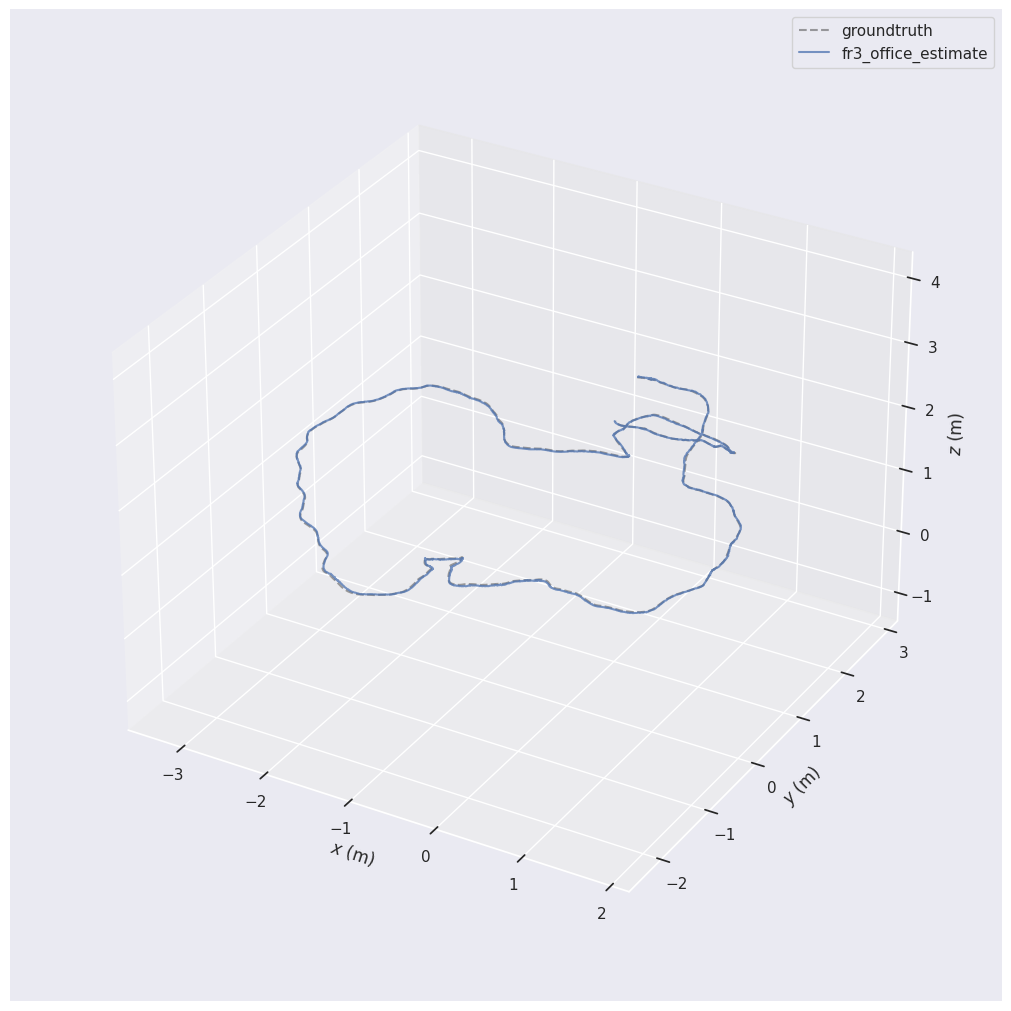

In [ ]:
from IPython.display import display, Image

display(Image(filename="/kaggle/working/fr3_office_trajectory_trajectories.png"))

In [ ]:
import zipfile
from pathlib import Path

output_files = [
    Path("/kaggle/working/fr3_office_estimate.txt"),
    Path("/kaggle/working/fr3_office_ape.zip"),
    Path("/kaggle/working/fr3_office_trajectory.png"),
]

with zipfile.ZipFile(
    "/kaggle/working/fr3_office_results.zip", "w"
) as zf:
    for file in output_files:
        if file.exists():
            zf.write(file, arcname=file.name)

print("Results:", "/kaggle/working/fr3_office_results.zip")

Results: /kaggle/working/fr3_office_results.zip


Matched poses: 2583
ATE RMSE (scale fitted): 0.0144 m
Scale fitted for ATE:    1.431011
SAD (scale = 1):         0.6072 m


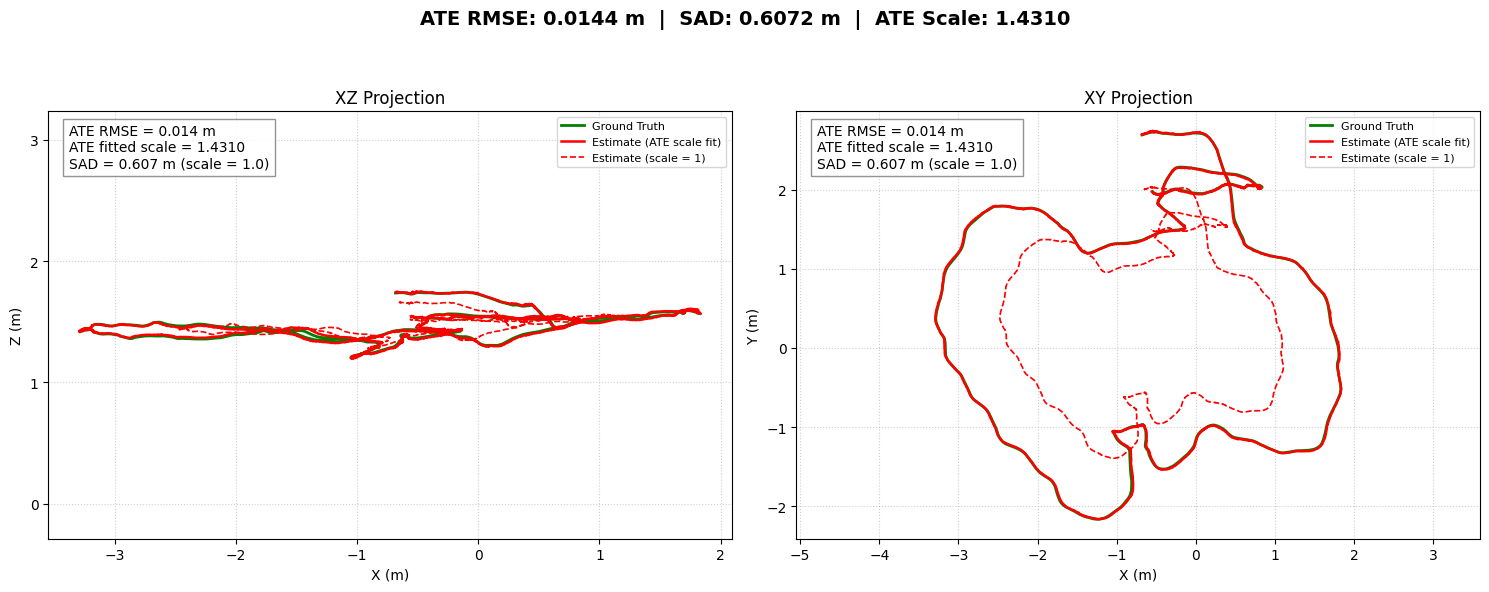

Saved image: /kaggle/working/droid_trajectory_comparison.png


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# Update these paths to your trajectory files
GT_PATH = "/kaggle/working/rgbd_dataset_freiburg3_long_office_household/groundtruth.txt"
EST_PATH = "/kaggle/working/fr3_office_estimate.txt"

# TUM format: timestamp tx ty tz qx qy qz qw
def load_tum(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            vals = [float(x) for x in line.split()]
            if len(vals) >= 8:
                rows.append(vals[:8])
    return np.asarray(rows, dtype=float)

gt_raw = load_tum(GT_PATH)
est_raw = load_tum(EST_PATH)

# Associate each estimated pose with the nearest GT timestamp
gt_t, gt_xyz = gt_raw[:, 0], gt_raw[:, 1:4]
est_t, est_xyz_all = est_raw[:, 0], est_raw[:, 1:4]

idx = np.searchsorted(gt_t, est_t)
idx = np.clip(idx, 0, len(gt_t) - 1)
prev = np.clip(idx - 1, 0, len(gt_t) - 1)
idx = np.where(
    np.abs(gt_t[prev] - est_t) < np.abs(gt_t[idx] - est_t),
    prev, idx
)

max_dt = 0.02  # maximum timestamp difference in seconds
valid = np.abs(gt_t[idx] - est_t) <= max_dt
X = est_xyz_all[valid]  # estimate
Y = gt_xyz[idx[valid]]  # corresponding ground truth

if len(X) < 3:
    raise ValueError(
        f"Only {len(X)} timestamp matches. Check the trajectory paths "
        "and timestamp units."
    )

# Umeyama alignment: transform estimate onto ground truth.
# With fit_scale=True, estimates the similarity scale.
# With fit_scale=False, scale is exactly 1.
def align_trajectory(X, Y, fit_scale=True):
    mx, my = X.mean(axis=0), Y.mean(axis=0)
    Xc, Yc = X - mx, Y - my

    U, S, Vt = np.linalg.svd(Yc.T @ Xc / len(X))
    D = np.eye(3)
    D[-1, -1] = np.linalg.det(U @ Vt)
    R = U @ D @ Vt

    if fit_scale:
        var_x = np.mean(np.sum(Xc**2, axis=1))
        scale = np.sum(S * np.diag(D)) / var_x
    else:
        scale = 1.0

    t = my - scale * (R @ mx)
    aligned = scale * (X @ R.T) + t
    return aligned, scale

# ATE comparison: rigid alignment + fitted scale
X_ate, fitted_scale = align_trajectory(X, Y, fit_scale=True)
ate_errors = np.linalg.norm(X_ate - Y, axis=1)
ATE_RMSE = np.sqrt(np.mean(ate_errors**2))

# SAD comparison: rigid alignment, scale fixed at exactly 1
X_sad, sad_scale = align_trajectory(X, Y, fit_scale=False)
sad_errors = np.linalg.norm(X_sad - Y, axis=1)
SAD = np.mean(sad_errors)

print(f"Matched poses: {len(X)}")
print(f"ATE RMSE (scale fitted): {ATE_RMSE:.4f} m")
print(f"Scale fitted for ATE:    {fitted_scale:.6f}")
print(f"SAD (scale = 1):         {SAD:.4f} m")

# Plot XZ and XY projections.
# Solid red = ATE scale-fitted trajectory.
# Dashed red = scale-1 trajectory used for SAD.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plots = [
    (axes[0], 0, 2, "X (m)", "Z (m)", "XZ Projection"),
    (axes[1], 0, 1, "X (m)", "Y (m)", "XY Projection"),
]

for ax, a, b, xlabel, ylabel, title in plots:
    ax.plot(Y[:, a], Y[:, b], color="green",
            linewidth=2, label="Ground Truth")
    ax.plot(X_ate[:, a], X_ate[:, b], color="red",
            linewidth=1.8, label="Estimate (ATE scale fit)")
    ax.plot(X_sad[:, a], X_sad[:, b], color="red",
            linestyle="--", linewidth=1.2,
            label="Estimate (scale = 1)")

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_aspect("equal", adjustable="datalim")
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.yaxis.set_major_locator(MultipleLocator(1.0))
    ax.grid(True, linestyle=":", alpha=0.6)

    metrics = (
        f"ATE RMSE = {ATE_RMSE:.3f} m\n"
        f"ATE fitted scale = {fitted_scale:.4f}\n"
        f"SAD = {SAD:.3f} m (scale = {sad_scale:.1f})"
    )
    ax.text(
        0.03, 0.97, metrics,
        transform=ax.transAxes, va="top", ha="left",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="gray")
    )
    ax.legend(loc="best", fontsize=8)

plt.tight_layout()
# Add a clear metrics summary directly onto the image
fig.suptitle(
    f"ATE RMSE: {ATE_RMSE:.4f} m  |  "
    f"SAD: {SAD:.4f} m  |  "
    f"ATE Scale: {fitted_scale:.4f}",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

output_path = "/kaggle/working/droid_trajectory_comparison.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved image: {output_path}")


In [ ]:
from pathlib import Path
import numpy as np

REPO = Path("/kaggle/working/DROID-SLAM")
ROOT = Path("/kaggle/working/KITTI")

# Handle either archive directory layout
candidates = [
    ROOT / "sequences/07",
    ROOT / "dataset/sequences/07",
]
SEQ = next((p for p in candidates if (p / "image_0").exists()), None)

assert SEQ is not None, "Could not find KITTI sequence 07/image_0"

GT_CANDIDATES = [
    ROOT / "poses/07.txt",
    ROOT / "dataset/poses/07.txt",
]
GT_PATH = next((p for p in GT_CANDIDATES if p.exists()), None)
assert GT_PATH is not None, "Could not find KITTI ground-truth poses"

calib_path = SEQ / "calib.txt"
assert calib_path.exists(), f"Missing calibration: {calib_path}"

calib_lines = {}
for line in calib_path.read_text().splitlines():
    key, values = line.split(":", 1)
    calib_lines[key.strip()] = np.fromstring(values, sep=" ")

P0 = calib_lines["P0"].reshape(3, 4)
fx, fy, cx, cy = P0[0, 0], P0[1, 1], P0[0, 2], P0[1, 2]

# DROID demo expects fx fy cx cy
DROID_CALIB = REPO / "calib/kitti07.txt"
DROID_CALIB.write_text(f"{fx} {fy} {cx} {cy}\n")

OUT = Path("/kaggle/working/results/kitti07_mono")
OUT.mkdir(parents=True, exist_ok=True)

print("Sequence:", SEQ)
print("GT:", GT_PATH)
print("Calibration:", DROID_CALIB)
print("Left frames:", len(list((SEQ / "image_0").glob("*.png"))))
print("Right frames:", len(list((SEQ / "image_1").glob("*.png"))))


Sequence: /kaggle/working/KITTI/dataset/sequences/07
GT: /kaggle/working/KITTI/dataset/poses/07.txt
Calibration: /kaggle/working/DROID-SLAM/calib/kitti07.txt
Left frames: 1101
Right frames: 1101


In [ ]:
%cd /kaggle/working/DROID-SLAM

!python demo.py \
    --imagedir="{SEQ / 'image_0'}" \
    --calib="{DROID_CALIB}" \
    --weights="droid.pth" \
    --stride=1 \
    --disable_vis \
    --reconstruction_path="{OUT / 'reconstruction.pth'}"

/kaggle/working/DROID-SLAM
0it [00:00, ?it/s]droid.pth
1101it [03:28,  5.28it/s]
################################
################################


In [ ]:
import torch

recon_path = OUT / "reconstruction.pth"
assert recon_path.exists(), "Inference did not produce a reconstruction file"

data = torch.load(recon_path, map_location="cpu", weights_only=False)

for key, value in data.items():
    if hasattr(value, "shape"):
        print(key, tuple(value.shape))
    else:
        print(key, type(value))

tstamps (394,)
images (394, 3, 240, 800)
disps (394, 240, 800)
poses (394, 7)
intrinsics (394, 4)


In [32]:

!unzip -q -o /kaggle/working/KITTI/poses.zip \
    -d /kaggle/working/KITTI/poses

/kaggle/working/DROID-SLAM
Reconstruction keys: ['tstamps', 'images', 'disps', 'poses', 'intrinsics']
Matched frames: 394
Estimated trajectory shape: (394, 3)
Ground-truth trajectory shape: (394, 3)

KITTI sequence 07 — monocular DROID-SLAM
Matched frames: 394
ATE RMSE (similarity alignment, scale fitted): 21.325355 m
SAD / mean position error (rigid alignment, scale fixed to 1): 74.145431 m
Fitted similarity scale: 7.834481



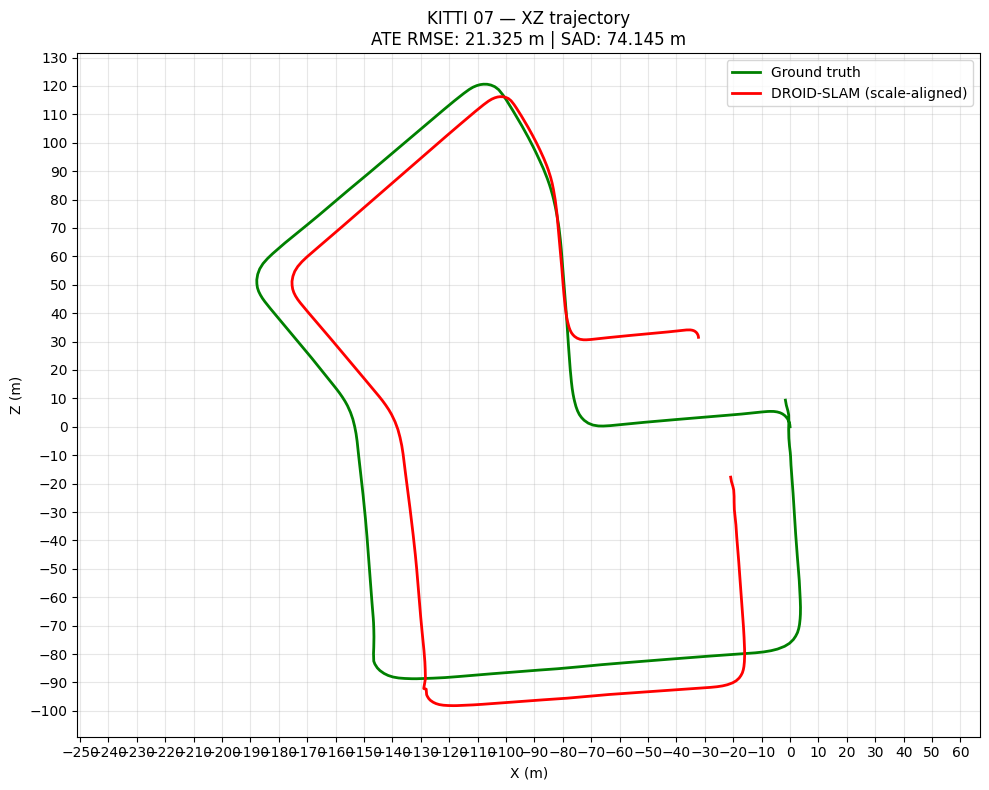

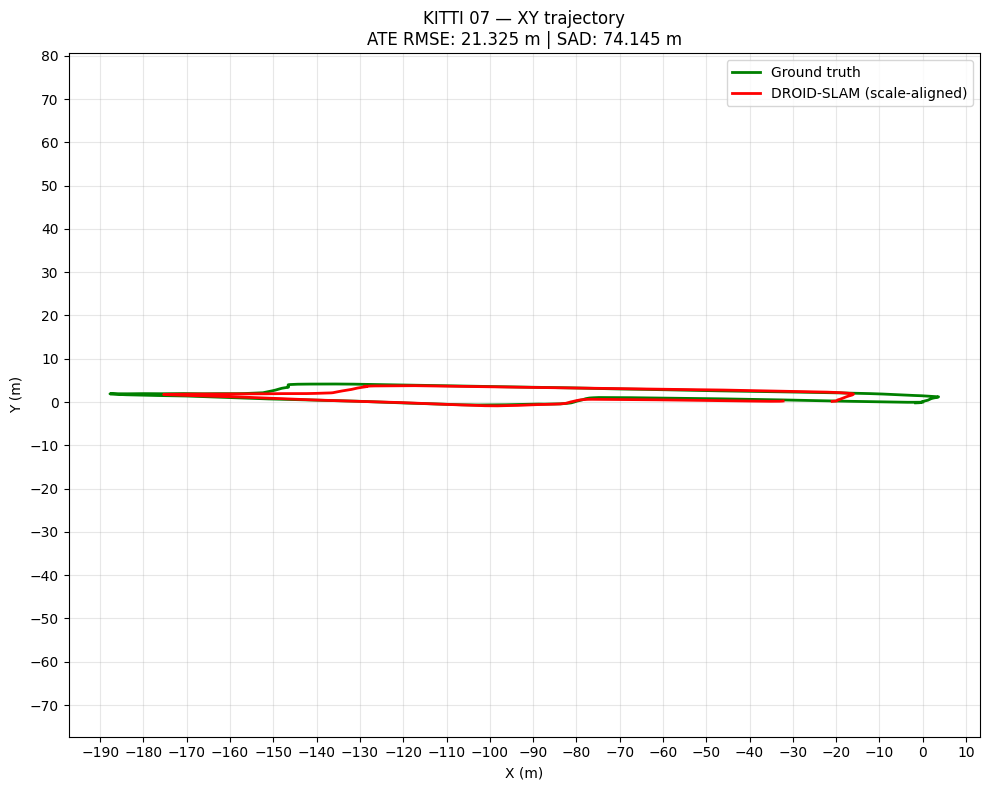

Saved comparison files:
 - XY.png
 - XZ.png
 - groundtruth_matched.txt
 - metrics.txt
 - reconstruction.pth
 - trajectory.txt


In [33]:
%cd /kaggle/working/DROID-SLAM

from pathlib import Path
import numpy as np
import torch
import lietorch
import matplotlib.pyplot as plt

# ---------- Paths ----------
RECON = Path(OUT) / "reconstruction.pth"
OUT = Path(OUT)
GT_POSES = Path("/kaggle/working/KITTI/dataset/poses/07.txt")

OUT.mkdir(parents=True, exist_ok=True)

assert RECON.exists(), f"Reconstruction not found: {RECON}"
assert GT_POSES.exists(), f"Ground-truth poses not found: {GT_POSES}"

# ---------- Load reconstruction and ground truth ----------
data = torch.load(RECON, map_location="cpu", weights_only=False)

print("Reconstruction keys:", list(data.keys()))
raw_poses = data["poses"].float()
timestamps = data["tstamps"].cpu().numpy().reshape(-1)

# demo.py stores the internal video poses. Invert them to obtain
# camera-to-world poses, consistent with the KITTI ground-truth poses.
estimated_poses = lietorch.SE3(raw_poses).inv().data.cpu().numpy()

# Camera-to-world translations: [tx, ty, tz, qx, qy, qz, qw]
est_xyz = estimated_poses[:, :3]

gt_matrices = np.loadtxt(GT_POSES).reshape(-1, 3, 4)
gt_xyz_all = gt_matrices[:, :, 3]

# Match frames using the stored frame indices.
frame_ids = timestamps.astype(int)
valid = (frame_ids >= 0) & (frame_ids < len(gt_xyz_all))
frame_ids = frame_ids[valid]
est_xyz = est_xyz[valid]
estimated_poses = estimated_poses[valid]
gt_xyz = gt_xyz_all[frame_ids]

# Exclude invalid GT rows if present.
valid_gt = np.isfinite(gt_xyz).all(axis=1)
frame_ids = frame_ids[valid_gt]
est_xyz = est_xyz[valid_gt]
estimated_poses = estimated_poses[valid_gt]
gt_xyz = gt_xyz[valid_gt]

assert len(gt_xyz) >= 3, "Too few matched poses for evaluation."

print("Matched frames:", len(gt_xyz))
print("Estimated trajectory shape:", est_xyz.shape)
print("Ground-truth trajectory shape:", gt_xyz.shape)

# ---------- Umeyama alignment ----------
def align_trajectory(source, target, fit_scale=True):
    """Align source to target using rotation, translation, and optional scale."""
    mu_s = source.mean(axis=0)
    mu_t = target.mean(axis=0)
    s0 = source - mu_s
    t0 = target - mu_t

    U, D, Vt = np.linalg.svd(t0.T @ s0 / len(source))
    S = np.eye(3)
    S[-1, -1] = np.linalg.det(U @ Vt)
    R = U @ S @ Vt

    if fit_scale:
        variance = np.mean(np.sum(s0**2, axis=1))
        scale = np.sum(D * np.diag(S)) / variance
    else:
        scale = 1.0

    aligned = scale * (source - mu_s) @ R.T + mu_t
    return aligned, float(scale)

# ATE: similarity alignment, including fitted scale.
est_ate, fitted_scale = align_trajectory(est_xyz, gt_xyz, fit_scale=True)
ate_errors = np.linalg.norm(est_ate - gt_xyz, axis=1)
ate_rmse = float(np.sqrt(np.mean(ate_errors**2)))

# SAD: mean Euclidean position error after rigid alignment, scale fixed at 1.
est_sad, _ = align_trajectory(est_xyz, gt_xyz, fit_scale=False)
sad_errors = np.linalg.norm(est_sad - gt_xyz, axis=1)
sad_mean = float(np.mean(sad_errors))

# ---------- Save estimated trajectory ----------
# TUM-style text: timestamp tx ty tz qx qy qz qw
# Poses are the raw camera-to-world estimates, not aligned poses.
trajectory_file = OUT / "trajectory.txt"
np.savetxt(
    trajectory_file,
    np.column_stack((frame_ids, estimated_poses)),
    fmt="%.9f",
    header="timestamp tx ty tz qx qy qz qw"
)

np.savetxt(
    OUT / "groundtruth_matched.txt",
    np.column_stack((frame_ids, gt_xyz)),
    fmt="%.9f",
    header="frame_index tx ty tz"
)

# ---------- Save metrics ----------
metrics = f"""KITTI sequence 07 — monocular DROID-SLAM
Matched frames: {len(gt_xyz)}
ATE RMSE (similarity alignment, scale fitted): {ate_rmse:.6f} m
SAD / mean position error (rigid alignment, scale fixed to 1): {sad_mean:.6f} m
Fitted similarity scale: {fitted_scale:.6f}
"""
(OUT / "metrics.txt").write_text(metrics)
print("\n" + metrics)

# ---------- Plot XZ and XY ----------
def plot_trajectory(gt, est, horizontal, vertical, filename, plane_name):
    fig, ax = plt.subplots(figsize=(10, 8))

    ax.plot(
        gt[:, horizontal], gt[:, vertical],
        color="green", label="Ground truth", linewidth=2
    )
    ax.plot(
        est[:, horizontal], est[:, vertical],
        color="red", label="DROID-SLAM (scale-aligned)", linewidth=2
    )

    axis_names = ["X", "Y", "Z"]
    ax.set_xlabel(f"{axis_names[horizontal]} (m)")
    ax.set_ylabel(f"{axis_names[vertical]} (m)")
    ax.set_title(f"KITTI 07 — {plane_name}\nATE RMSE: {ate_rmse:.3f} m | SAD: {sad_mean:.3f} m")
    ax.grid(True, alpha=0.3)
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend()

    # Meter tick spacing, chosen to keep the plot readable.
    ax.xaxis.set_major_locator(plt.MultipleLocator(10))
    ax.yaxis.set_major_locator(plt.MultipleLocator(10))

    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

plot_trajectory(gt_xyz, est_ate, 0, 2, "XZ.png", "XZ trajectory")
plot_trajectory(gt_xyz, est_ate, 0, 1, "XY.png", "XY trajectory")

print("Saved comparison files:")
for path in sorted(OUT.iterdir()):
    print(f" - {path.name}")

In [35]:
%cd /kaggle/working

!wget -c http://robotics.ethz.ch/~asl-datasets/ijrr_euroc_mav_dataset/machine_hall/MH_01_easy/MH_01_easy.zip \
    -O MH_01_easy.zip

!unzip -q -o MH_01_easy.zip -d /kaggle/working/EuRoC

/kaggle/working
--2026-10-16 08:02:28--  http://robotics.ethz.ch/~asl-datasets/ijrr_euroc_mav_dataset/machine_hall/MH_01_easy/MH_01_easy.zip
Resolving robotics.ethz.ch (robotics.ethz.ch)... 129.132.38.186
Connecting to robotics.ethz.ch (robotics.ethz.ch)|129.132.38.186|:80... failed: Connection timed out.
Retrying.

--2026-10-16 08:04:44--  (try: 2)  http://robotics.ethz.ch/~asl-datasets/ijrr_euroc_mav_dataset/machine_hall/MH_01_easy/MH_01_easy.zip
Connecting to robotics.ethz.ch (robotics.ethz.ch)|129.132.38.186|:80... failed: Connection timed out.
Retrying.

--2026-10-16 08:07:00--  (try: 3)  http://robotics.ethz.ch/~asl-datasets/ijrr_euroc_mav_dataset/machine_hall/MH_01_easy/MH_01_easy.zip
Connecting to robotics.ethz.ch (robotics.ethz.ch)|129.132.38.186|:80... failed: Connection timed out.
Retrying.

--2026-10-16 08:09:16--  (try: 4)  http://robotics.ethz.ch/~asl-datasets/ijrr_euroc_mav_dataset/machine_hall/MH_01_easy/MH_01_easy.zip
Connecting to robotics.ethz.ch (robotics.ethz.ch)|1

In [ ]:
from pathlib import Path

DATA = Path("/kaggle/working/EuRoC/MH_01_easy")

for cam in ["cam0", "cam1"]:
    image_dir = DATA / "mav0" / cam / "data"
    images = sorted(image_dir.glob("*.png"))
    print(f"{cam}: {len(images)} images")
    if images:
        print("First image:", images[0].name)

print("Ground truth exists:",
      (DATA / "mav0/state_groundtruth_estimate0/data.csv").exists())

In [ ]:
SEQ_NAME = "MH_01_easy"
DATA = Path("/kaggle/working/EuRoC") / SEQ_NAME

RESULTS = Path("/kaggle/working/results/EuRoC") / SEQ_NAME
MONO_OUT = RESULTS / "mono"
STEREO_OUT = RESULTS / "stereo"

MONO_OUT.mkdir(parents=True, exist_ok=True)
STEREO_OUT.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA)
print("Monocular output:", MONO_OUT)
print("Stereo output:", STEREO_OUT)

In [34]:
%cd /kaggle/working/DROID-SLAM

from pathlib import Path
import subprocess
import sys

REPO = Path("/kaggle/working/DROID-SLAM")
SEQ_NAME = "MH_01_easy"

DATA = REPO / "datasets/EuRoC" / SEQ_NAME
GT = REPO / "data/euroc_groundtruth" / f"{SEQ_NAME}.txt"
WEIGHTS = REPO / "droid.pth"

RESULTS = Path("/kaggle/working/results/EuRoC") / SEQ_NAME
MONO_OUT = RESULTS / "mono"
STEREO_OUT = RESULTS / "stereo"

for folder in (MONO_OUT, STEREO_OUT):
    folder.mkdir(parents=True, exist_ok=True)

assert (DATA / "mav0/cam0/data").exists(), f"Missing left camera images: {DATA}"
assert (DATA / "mav0/cam1/data").exists(), f"Missing right camera images: {DATA}"
assert GT.exists(), f"Missing ground truth: {GT}"
assert WEIGHTS.exists(), f"Missing checkpoint: {WEIGHTS}"

print("Sequence:", SEQ_NAME)
print("Ground truth:", GT)
print("Results:", RESULTS)

/kaggle/working/DROID-SLAM


AssertionError: Missing left camera images: /kaggle/working/DROID-SLAM/datasets/EuRoC/MH_01_easy

In [ ]:
%cd /kaggle/working/DROID-SLAM

cmd = [
    sys.executable,
    "evaluation_scripts/test_euroc.py",
    f"--datapath={DATA}",
    f"--gt={GT}",
    f"--weights={WEIGHTS}",
    "--disable_vis",
]

with open(MONO_OUT / "evaluation.log", "w") as log:
    result = subprocess.run(
        cmd, cwd=str(REPO), stdout=log,
        stderr=subprocess.STDOUT, text=True
    )

print((MONO_OUT / "evaluation.log").read_text()[-5000:])
if result.returncode != 0:
    raise RuntimeError("Monocular evaluation failed. Check evaluation.log.")

In [ ]:
cmd = [
    sys.executable,
    "evaluation_scripts/test_euroc.py",
    f"--datapath={DATA}",
    f"--gt={GT}",
    f"--weights={WEIGHTS}",
    "--disable_vis",
    "--stereo",
]

with open(STEREO_OUT / "evaluation.log", "w") as log:
    result = subprocess.run(
        cmd, cwd=str(REPO), stdout=log,
        stderr=subprocess.STDOUT, text=True
    )

print((STEREO_OUT / "evaluation.log").read_text()[-5000:])
if result.returncode != 0:
    raise RuntimeError("Stereo evaluation failed. Check evaluation.log.")